# Pré processamento da imagem

## Conversão para a escala de cinza 
- Imagens coloridas, possuem 3 canais (**R, G, B**) e reduzi-las para apenas 1 canal(**Escala de Cinza**) ajuda a reduxir o custo computacional - visto que processamos 3x menos dados - e melhorar o processso dos algoritmos de detecção de bordas 
- Existem 3 formas de converter para escala de cinza 
1. **MÉDIA SIMPLES**: I = (R + G + B) / 3
2. **LUMINÂNCIA (BT.601)**: I = 0.299·R + 0.587·G + 0.114·B (Pondera os pinxels de acordo com a percepção humana)
3. **LUMINÂNCIA (BT.709)**: I = 0.2126·R + 0.7152·G + 0.0722 (Dá um peso maior para o verde)

- No codigo abaixo vamos usar **LUMINÂNCIA (BT.601)**, porque é padrão do cv2

In [8]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt

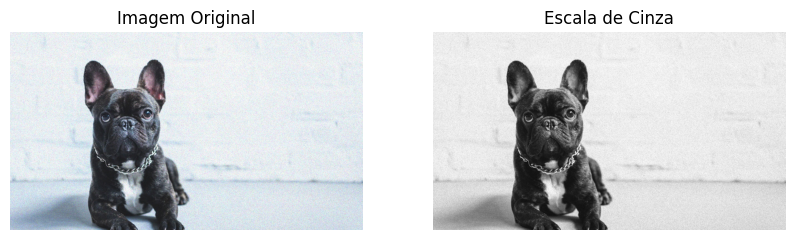

In [10]:
#Carregando a imagem 
img_bgr = cv2.imread('dog.jpg')
if img_bgr is None:
    raise FileNotFoundError("A imagem 'dog.jpg' nao foi encontrada na pasta do notebook.")
img_colorida = img_bgr[:, :, ::-1] # invertemos BGR para RGB

#Separando as matrizes
R = img_colorida[:,:,0]
G = img_colorida[:,:,1]
B = img_colorida[:,:,2]

#Aplicando fórmula de LUMINÂNCIA (BT.601):
img_cinza = 0.299*R + 0.587*G + 0.114*B

#Visualizando 
plt.figure(figsize=(10,5)) #define a largura da imagem
plt.subplot(1, 2, 1)
plt.title('Imagem Original')
plt.imshow(img_colorida)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Escala de Cinza')
plt.imshow(img_cinza, cmap='gray')
plt.axis('off')

plt.show()

## Suavização
Para realizar o processo de suavização existem 3 maneiras:
1. **Filtro média (mean / box filter)**: Substitui cada pixel pela média aritmética dos pixels da sua vizinhança
2. **Filtro mediana**: Substitui cada pixel pela mediana (valor central ordenado) dos pixels da vizinhança.
3. **Filtro gaussiano**: Convolução com um kernel cujos pesos seguem uma função gaussiana 2D — pixels mais próximos do
centro têm peso maior.

Iremos utilizar o filtro Gaussiano pelo resultado mais natural com a fórmula **G(x, y) = (1 / 2πσ²) · exp(−(x² + y²) / 2σ²)**

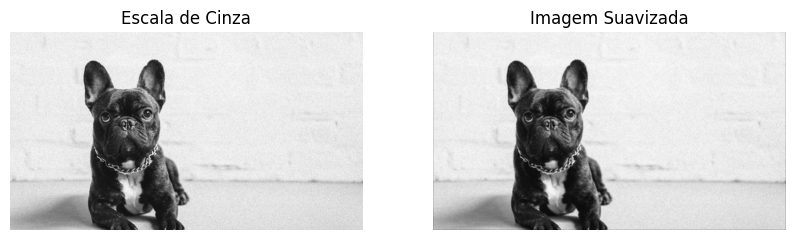

In [11]:
def criar_kernel(tm, sigma):
    #O tamanho precisa ser ímpara para ter um pixel central
    k = tm // 2
    x, y = np. mgrid[-k:k+1, -k:k+1]

    #Aplicando a fórmula G(x, y) do material: G(x, y) = (1 / 2πσ²) · exp(−(x² + y²) / 2σ²)
    t1 = 1.0/(2.0 * np.pi * sigma**2)
    t2 = np.exp((x**2 +(y**2))/(2.0 * sigma**2))
    kernel = t1*t2
    #Normalizamos dividindo pela soma
    return kernel/ kernel.sum()

def convulacao(img, kernel):
    h_img, l_img = img.shape 
    h_k, l_k = kernel.shape
    #Adicionando margem(padding) 
    pad_h = h_k//2
    pad_w = l_k//2
    #Borda de pixels pretos(zero) ao redor da imagem
    img_pad = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant')
    #Matriz vazia para guardar resultado
    resultado = np.zeros_like(img, dtype=np.float32)
    for i in range(h_img):
        for j in range(l_img):
            #Recorta a região atual no memo tamanho do Kernel
            regiao = img_pad[i:i+h_k, j:j+l_k]
            #Operação de Covulação: Multiplica a região pelo Kernel e soma tudo 
            resultado[i, j] = np.sum(regiao * kernel)
    #Garantindo que o resultado fique entre 0 e 255
    return np.clip(resultado, 0, 255).astype(np.uint8)

#Vamos usar valores comuns para a análise: 3x3
k_gausssiano = criar_kernel(3, 1.4) 
img_suavizada = convulacao(img_cinza, k_gausssiano)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Escala de Cinza')
plt.imshow(img_cinza, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Imagem Suavizada')
plt.imshow(img_suavizada, cmap='gray')
plt.axis('off')

plt.show()


## Detecção de Bordas 
- Bordas são regiões da imagem onde a intensidade das cores muda rapidamente, ou seja, uma zona em que ocorre uma transição forte entre dois conjuntos de pixels. Matematicamente: locais com gradiente alto (derivada espacial alta).


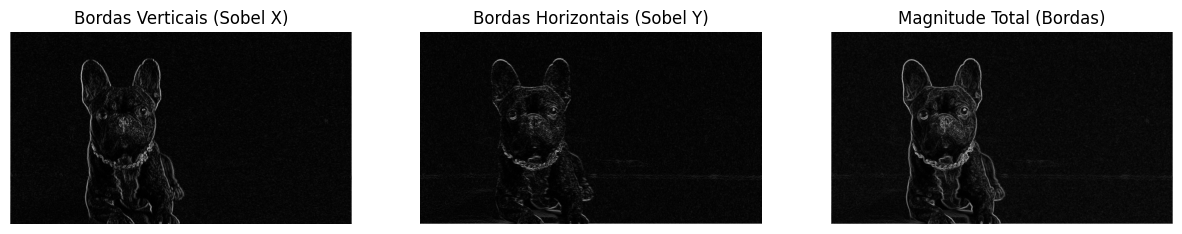

In [12]:
#1. Definindo os Kernels do Operador Soble(3x3)
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype=np.float32)
sobel_y = np.array([[-1, -2, -1],
                    [0, 0, 0],
                    [1, 2, 1]], dtype=np.float32)
#2. Convulação para o sobel
def filtro(img, kernel):
    h_img, l_img = img.shape 
    h_k, l_k = kernel.shape
    #Adicionando margem(padding) 
    pad_h = h_k//2
    pad_w = l_k//2
    #Borda de pixels pretos(zero) ao redor da imagem
    img_pad = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode='edge')
    #Matriz vazia para guardar resultado
    resultado = np.zeros_like(img, dtype=np.float32)
    for i in range(h_img):
        for j in range(l_img):
            #Recorta a região atual no memo tamanho do Kernel
            regiao = img_pad[i:i+h_k, j:j+l_k]
            #Operação de Covulação: Multiplica a região pelo Kernel e soma tudo 
            resultado[i, j] = np.sum(regiao * kernel)
    #Garantindo que o resultado fique entre 0 e 255
    return resultado
#3. Aplicando os kernels a imagem suavizada
gradiente_x = filtro(img_suavizada, sobel_x)
gradiente_y = filtro(img_suavizada, sobel_y)

#4. Calculando a Magnitude da Borda
#Combinando bordas verticais e horizontais com o Teorema de Pitagoras
magnitude = np.sqrt(gradiente_x**2 + gradiente_y**2)
#Normalizando entre 0-255 para poder plotar como imagem
magnitude = (magnitude/magnitude.max() * 255)
img_bordas = magnitude.astype(np.uint8)

#Visualização
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.title('Bordas Verticais (Sobel X)')
plt.imshow(np.abs(gradiente_x), cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title('Bordas Horizontais (Sobel Y)')
plt.imshow(np.abs(gradiente_y), cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title('Magnitude Total (Bordas)')
plt.imshow(img_bordas, cmap='gray')
plt.axis('off')

plt.show()


## Detecção de Bordas de Canny e Mapeamento Espacial
Implementaremos e analisaremos três etapas sequenciais fundamentais do Detector de Bordas de Canny:
1. **Supressão de Não-Máximos:** Um filtro geométrico que analisa a direção ortogonal do gradiente para afinar os contornos, reduzindo linhas largas à espessura matemática de apenas 1 pixel.
2. **Limiarização Dupla:** Uma filtragem de intensidade adaptativa baseada em dois limiares ($limiar\_alto$ e $limiar\_baixo$) que categoriza os pixels em bordas fortes, fracas ou ruído eliminatório.
3. **Conversão e Mapeamento para o Espaço de Trabalho do Robô:** A extração das coordenadas dos pixels validados e sua devida transposição matemática (ajuste de escala, translação e inversão do eixo vertical) para os limites operacionais lógicos ($0$ a $11$) da tela do robô.

### 1. Tratamento de ângulos e configuração
- O primeiro passo lógico consiste em processar as matrizes de gradiente originárias das etapas anteriores. Utilizamos a função np.arctan2 para obter a direção do vetor gradiente em radianos. Como a orientação geométrica da borda é simétrica em $180^\circ$ para o propósito de filtragem de Canny, todos os ângulos negativos obtidos são rotacionados para o intervalo estritamente positivo de $0^\circ$ a $180^\circ$.

In [13]:
# --- PREPARAÇÃO DOS ÂNGULOS DO GRADIENTE ---
# Calcula o arco-tangente de y/x obtendo o ângulo em radianos
angulo = np.arctan2(gradiente_y, gradiente_x)

# Converte os radianos para graus num intervalo de -180 a 180
angulo = np.rad2deg(angulo)

# Normaliza os ângulos negativos para o intervalo positivo correspondente [0, 180]
angulo[angulo < 0] += 180

### 2. Supressão de Não-Máximos
- A *supressão* varre pixel por pixel para isolar blocos de maior magnitude
- O algoritmo aproxima o ângulo contínuo medido para uma das quatro direções discretas do grid numérico ($0^\circ$, $45^\circ$, $90^\circ$ ou $135^\circ$).
1. **Geometria Ortogonal:** Se o gradiente aponta para uma direção, a borda física corre perpendicular a ele. Logo, para validar se o pixel atual é o topo da crista da borda, ele deve ser comparado diretamente com seus vizinhos situados na mesma linha de ação do gradiente.
2. **Decisão:** Se o pixel central possuir magnitude estritamente maior ou igual a ambos os vizinhos testados, ele é preservado; caso contrário, seu valor é zerado (suprimido).

In [14]:
def supressao(magnitude, angulo):
    h, l = magnitude.shape
    resultado = np.zeros((h, l), dtype=np.float32)

    for i in range(1, h-1):
        for j in range(1, l-1):
            q = 0
            r = 0
            
            # 1. Gradiente na direção Horizontal (~0° ou 180°) -> Teste nos vizinhos laterais
            if (0 <= angulo[i, j] < 22.5) or (157.5 <= angulo[i, j] <= 180):
                q = magnitude[i, j+1]
                r = magnitude[i, j-1]
                
            # 2. Gradiente na direção Diagonal Nordeste (~45°) -> Teste na diagonal secundária
            elif (22.5 <= angulo[i, j] < 67.5):
                q = magnitude[i-1, j+1]
                r = magnitude[i+1, j-1]
                
            # 3. Gradiente na direção Vertical (~90°) -> Teste nos vizinhos verticalmente alinhados
            elif (67.5 <= angulo[i, j] < 112.5):
                q = magnitude[i-1, j]
                r = magnitude[i+1, j]
                
            # 4. Gradiente na direção Diagonal Noroeste (~135°) -> Teste na diagonal principal
            elif (112.5 <= angulo[i, j] < 157.5):
                q = magnitude[i-1, j-1]
                r = magnitude[i+1, j+1]
            
            # Avaliação de Máximo Local
            if (magnitude[i, j] >= q) and (magnitude[i, j] >= r):
                resultado[i, j] = magnitude[i, j]
            else:
                resultado[i, j] = 0 # Supressão aplicada
                
    return resultado

# Executa o algoritmo de afinamento de bordas
img_supressa = supressao(magnitude, angulo)

## 

### 3. Limiarização Dupla
A função limiarizacao reduz a ambiguidade de bordas fracas geradas por variações sutis de textura ou iluminação. Estabelecemos dois limiares proporcionais à intensidade de pico (img.max()):

- Bordas Fortes (Branco Puro - 255): Valores acima do limiar alto. São consideradas estruturalmente válidas.

- Bordas Fracas (Cinza - 75): Valores que flutuam na zona intermediária entre os dois limiares. Ficam em estado de espera para avaliação de conectividade.

- Eliminação (Preto - 0): Ruídos abaixo do limiar mínimo são sumariamente expurgados da imagem.

In [24]:
def limiarizacao(img, limiar_baixo_ratio=0.4, limiar_alto_ratio=0.3):
    # Cálculo adaptativo dos limites operacionais
    limiar_alto = img.max() * limiar_alto_ratio
    limiar_baixo = limiar_alto * limiar_baixo_ratio
    resultado = np.zeros_like(img)

    # Definição das intensidades de classe para visualização
    fraco = np.int32(75)  
    forte = np.int32(255) 

    # Classificação vetorizada eficiente usando filtros do NumPy
    forte_i, forte_j = np.where(img >= limiar_alto)
    fraco_i, fraco_j = np.where((img < limiar_alto) & (img >= limiar_baixo))

    # Construção da imagem segmentada
    resultado[forte_i, forte_j] = forte
    resultado[fraco_i, fraco_j] = fraco

    return resultado, fraco, forte

# Executa a filtragem por limiares estruturais
img_limiarizada, valor_fraco, valor_forte = limiarizacao(img_supressa)

### 4. Transformação Homogênea para Coordenadas do Robô

- Uma vez filtrados os contornos úteis na imagem digital, as coordenadas discretas dos pixels pertencentes às bordas ativas são extraídas.  O espaço de trabalho de exibição matricial de uma imagem tem sua origem (0,0) posicionada no canto superior esquerdo, crescendo para baixo. Por outro lado, o plano cartesiano de navegação do Turtlesim possui sua origem no canto inferior esquerdo.Para corrigir essa incompatibilidade espacial e escalar a geometria sem gerar distorções de aspecto (aspect ratio), aplicamos a transformação matemática:
$$turtle\_x = (img\_x \cdot escala) + 0.5$$$$turtle\_y = ((altura\_img - img\_y) \cdot escala) + 0.5$$O 
fator de segurança de +0.5 funciona como uma margem física de proteção para que a tartaruga não colida e fique travada nas paredes limítrofes do simulador ROS

In [25]:
# 1. Extração dos pontos de interesse pós-processamento 
# (Simulando o uso da imagem final estabilizada)
linhas, colunas = np.where(img_limiarizada == 255)

altura_img, largura_img = img_limiarizada.shape
tamanho_turtlesim = 10.0  # Espaço útil seguro dentro do limite de 11.0 do ROS

# 2. Cálculo do fator de escala preservando as proporções originais
escala_x = tamanho_turtlesim / largura_img
escala_y = tamanho_turtlesim / altura_img
escala = min(escala_x, escala_y)

caminho_x = []
caminho_y = []

# 3. Laço de mapeamento e inversão matricial para cartesiano
for i in range(len(linhas)):
    img_y = linhas[i]
    img_x = colunas[i]
    
    # Mapeamento do eixo X
    tx = (img_x * escala) + 0.5
    # Mapeamento com inversão de orientação do eixo Y
    ty = ((altura_img - img_y) * escala) + 0.5
    
    caminho_x.append(tx)
    caminho_y.append(ty)

### 5. Saída


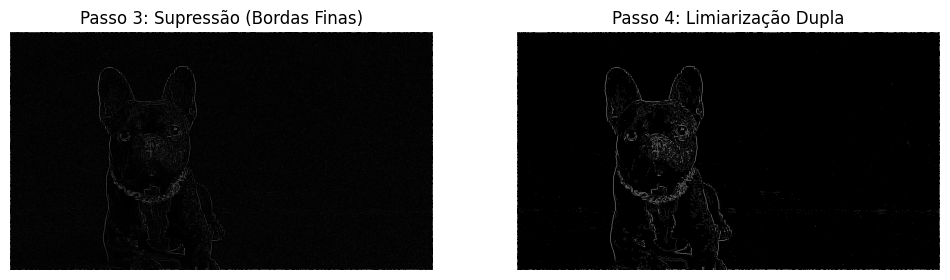

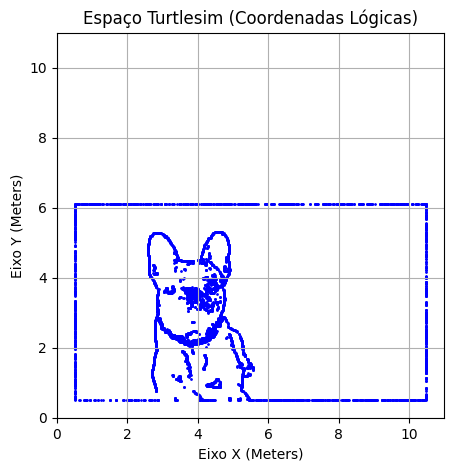

In [26]:
# --- RENDERIZAÇÃO DOS MAPAS DE VISÃO COMPUTACIONAL ---
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.title('Passo 3: Supressão (Bordas Finas)')
plt.imshow(img_supressa, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Passo 4: Limiarização Dupla')
plt.imshow(img_limiarizada, cmap='gray')
plt.axis('off')
plt.show()

# --- RENDERIZAÇÃO DO ESPAÇO OPERACIONAL DO ROBÔ ---
plt.figure(figsize=(5, 5))
plt.title('Espaço Turtlesim (Coordenadas Lógicas)')
plt.scatter(caminho_x, caminho_y, s=1, c='blue')
plt.xlim(0, 11)
plt.ylim(0, 11)
plt.grid(True)
plt.xlabel('Eixo X (Meters)')
plt.ylabel('Eixo Y (Meters)')
plt.show()